# Taller 1 — Regresión: Predicción de precios de viajes de Uber

**Aprendizaje de Máquina Aplicado — Universidad EAFIT**

Realizar por: Jhon Fredy Alzate Duque

Dataset: [Uber Ride Price Prediction](https://www.kaggle.com/datasets/kushsheth/uber-ride-price-prediction) (Kaggle).

Este notebook sigue las Fases 1 a 9 del taller para el problema de **regresión**: predecir el valor de la tarifa (`fare_amount`) de un viaje de Uber en Nueva York a partir de las coordenadas de recogida/destino, la fecha/hora y el número de pasajeros.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7, 4)
pd.set_option('display.max_columns', 50)
np.random.seed(RANDOM_STATE)

## Fase 1 — EDA, limpieza y preprocesamiento

### 1. Problema de negocio y variable objetivo

**Problema de negocio:** Uber (y cualquier plataforma de *ride-hailing*) necesita **estimar el precio de un viaje antes de que este ocurra**, con base en el origen, el destino, la hora y otros factores. Esta estimación se usa para:

- Mostrarle al usuario un precio estimado antes de confirmar el viaje.
- Detectar tarifas anómalas (errores de cobro, fraude).
- Analizar qué factores explican variaciones en el precio (distancia, hora pico, día de la semana, etc.) para apoyar decisiones de *pricing* dinámico.

**Variable objetivo (target):** `fare_amount` — el valor de la tarifa cobrada por el viaje, en USD. Es una variable numérica continua, por lo tanto este es un **problema de regresión**.

**Meta medible:** entrenar un modelo que prediga `fare_amount` minimizando el error absoluto medio (MAE) y maximizando el R² sobre datos nunca vistos (conjunto de prueba).


### 2. Carga de datos y diccionario de datos

In [2]:
df = pd.read_csv('data/uber.csv')
print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.tail()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
199995,42598914,49:00.0,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,09:00.0,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,42:00.0,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,56:25.0,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695416,1
199999,11951496,08:00.0,14.1,2010-05-15 04:08:00 UTC,-73.984395,40.720077,-73.985508,40.768793,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


**Diccionario de datos (versión original, antes de limpiar):**

| Columna | Tipo esperado | Significado |
|---|---|---|
| `Unnamed: 0` | entero | Índice residual guardado al exportar el CSV original. No aporta información — se elimina. |
| `key` | texto | Identificador interno del viaje (aparenta ser un timestamp truncado). Es redundante con `pickup_datetime` y no es una característica predictiva — se elimina. |
| `fare_amount` | float | **Variable objetivo.** Tarifa cobrada por el viaje, en USD. |
| `pickup_datetime` | texto (fecha/hora) | Fecha y hora de inicio del viaje, en UTC. Se transformará en varias características (año, mes, día, hora, día de la semana). |
| `pickup_longitude`, `pickup_latitude` | float | Coordenadas geográficas del punto de recogida. |
| `dropoff_longitude`, `dropoff_latitude` | float | Coordenadas geográficas del punto de destino. |
| `passenger_count` | entero | Número de pasajeros declarados en el viaje. |

Con `df.info()` confirmamos que hay **200,000 filas y 9 columnas**, y que casi todas las columnas están completas excepto `dropoff_longitude`/`dropoff_latitude`, que revisaremos en el punto 4.


### 3. Estadística descriptiva

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200000.0,2.771250e+07,1.601382e+07,1.000000,1.382535e+07,2.774550e+07,4.155530e+07,5.542357e+07
fare_amount,200000.0,1.135996e+01,9.901776e+00,-52.000000,6.000000e+00,8.500000e+00,1.250000e+01,4.990000e+02
pickup_longitude,200000.0,-7.252764e+01,1.143779e+01,-1340.648410,-7.399206e+01,-7.398182e+01,-7.396715e+01,5.741846e+01
pickup_latitude,200000.0,3.993589e+01,7.720539e+00,-74.015515,4.073480e+01,4.075259e+01,4.076716e+01,1.644421e+03
dropoff_longitude,199999.0,-7.252529e+01,1.311741e+01,-3356.666300,-7.399141e+01,-7.398009e+01,-7.396366e+01,1.153573e+03
dropoff_latitude,199999.0,3.992389e+01,6.794829e+00,-881.985513,4.073382e+01,4.075304e+01,4.076800e+01,8.726976e+02
passenger_count,200000.0,1.684535e+00,1.385997e+00,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,2.080000e+02


**Interpretación de al menos 3 estadísticos:**

- **`fare_amount`**: la media es **11.36 USD** y la mediana **8.5 USD** — la media está por encima de la mediana, lo que indica una distribución **sesgada a la derecha** (hay viajes caros que jalan el promedio hacia arriba, como viajes largos o al aeropuerto). El **mínimo es -52 USD**, lo cual **no tiene sentido de negocio** (una tarifa no puede ser negativa) y es evidencia de errores de captura que se deben limpiar (punto 4/7).
- **`passenger_count`**: el 75% de los viajes tiene como máximo 2 pasajeros, pero el **máximo registrado es 208**, un valor claramente imposible para un vehículo de Uber (capacidad típica 1-6 personas). Es un error de captura.
- **`pickup_latitude` / `pickup_longitude`**: Nueva York está aproximadamente en latitud 40.5–41.0 y longitud -74.3 a -73.7. Sin embargo, el **mínimo de `pickup_latitude` es -74.0** y el **máximo de `pickup_longitude` es 57.4**, valores geográficamente imposibles para Nueva York (de hecho, saldrían del rango válido de latitud/longitud terrestre en algunos casos). Esto confirma errores de GPS que deben filtrarse.

Estas tres observaciones ya anticipan gran parte del trabajo de limpieza que se hace en el punto 7.


### 4. Valores nulos

In [6]:
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df) * 100).round(4)
pd.DataFrame({'nulos': nulos, 'pct_nulos (%)': pct_nulos})

,nulos,pct_nulos (%)
Unnamed: 0,0,0.0000
key,0,0.0000
fare_amount,0,0.0000
pickup_datetime,0,0.0000
pickup_longitude,0,0.0000
pickup_latitude,0,0.0000
dropoff_longitude,1,0.0005
dropoff_latitude,1,0.0005
passenger_count,0,0.0000


**Estrategia de imputación/eliminación:** solo `dropoff_longitude` y `dropoff_latitude` tienen valores nulos, y en ambos casos es **una sola fila de 200,000 (0.0005%)**. Con un porcentaje de nulos tan bajo:

- **Imputar** (por ejemplo con la media) **no tiene sentido de negocio**: una coordenada de destino "promedio" no representa una ubicación real y podría introducir ruido geográfico sin ningún beneficio, ya que es una única fila.
- **Eliminar la fila** es la decisión correcta: el impacto en el tamaño del dataset es nulo (pasamos de 200,000 a 199,999 filas) y evitamos inventar una ubicación falsa.


In [7]:
df = df.dropna(subset=['dropoff_longitude', 'dropoff_latitude']).reset_index(drop=True)
print(f"Filas después de eliminar nulos: {df.shape[0]}")

Filas después de eliminar nulos: 199999


### 5. Duplicados

In [8]:
n_dup = df.duplicated().sum()
print(f"Número de filas duplicadas: {n_dup}")

Número de filas duplicadas: 0


No se encontraron filas completamente duplicadas (0 de 199,999). Esto es razonable: cada fila representa un viaje individual con un `pickup_datetime` casi siempre distinto, por lo que dos filas idénticas en todas las columnas serían muy poco probables. No se elimina ninguna fila en este punto.


### 6. Inconsistencias de formato

In [9]:
print(df['pickup_datetime'].head())
print(df['pickup_datetime'].dtype)

0    2015-05-07 19:52:06 UTC
1    2009-07-17 20:04:56 UTC
2    2009-08-24 21:45:00 UTC
3    2009-06-26 08:22:21 UTC
4    2014-08-28 17:47:00 UTC
Name: pickup_datetime, dtype: str
str


La única columna de texto con estructura fija es `pickup_datetime`, con formato `"YYYY-MM-DD HH:MM:SS UTC"` de manera consistente en todas las filas (no hay mayúsculas/minúsculas mezcladas, espacios adicionales, ni etiquetas equivalentes que corregir, como sí podría pasar con una columna categórica de texto libre). La columna `key` (ya eliminada) tenía un formato inconsistente/truncado, otra razón adicional para haberla descartado en vez de "arreglarla". El resto de columnas son numéricas y no aplica este punto.

Lo que sí se necesita es **convertir** `pickup_datetime` de texto a un tipo `datetime` real, lo cual se hace como parte de la ingeniería de características en el punto 7.


### 7. Outliers (criterio IQR) e ingeniería de características

Antes de calcular outliers de forma aislada, primero corregimos los errores evidentes que ya detectamos en el punto 3 (coordenadas fuera de Nueva York, tarifas negativas, número de pasajeros imposible) y construimos nuevas variables a partir de los datos crudos — esto es **ingeniería de características**, tal como se vio en clase (Lecture01b).

In [10]:
df = df.drop(columns=['Unnamed: 0', 'key'])

# --- Ingeniería de características a partir de pickup_datetime ---
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'].str.replace(' UTC', ''), format='%Y-%m-%d %H:%M:%S')
df['anio'] = df['pickup_datetime'].dt.year
df['mes'] = df['pickup_datetime'].dt.month
df['hora'] = df['pickup_datetime'].dt.hour
df['dia_semana'] = df['pickup_datetime'].dt.dayofweek  # 0 = lunes, 6 = domingo
df['es_finde'] = df['dia_semana'].isin([5, 6]).astype(int)

def franja_horaria(h):
    if 5 <= h < 12:
        return 'Mañana'
    if 12 <= h < 18:
        return 'Tarde'
    if 18 <= h < 22:
        return 'Noche'
    return 'Madrugada'

df['franja_horaria'] = df['hora'].apply(franja_horaria)

print("Años presentes en los datos:", sorted(df['anio'].unique()))
df[['pickup_datetime', 'anio', 'mes', 'hora', 'dia_semana', 'es_finde', 'franja_horaria']].head()

Años presentes en los datos: [np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015)]


,pickup_datetime,anio,mes,hora,dia_semana,es_finde,franja_horaria
0,2015-05-07 19:52:06,2015,5,19,3,0,Noche
1,2009-07-17 20:04:56,2009,7,20,4,0,Noche
2,2009-08-24 21:45:00,2009,8,21,0,0,Noche
3,2009-06-26 08:22:21,2009,6,8,4,0,Mañana
4,2014-08-28 17:47:00,2014,8,17,3,0,Tarde


**Intuición (¿qué información usaría un humano para predecir el precio de un viaje?):** claramente, la **distancia recorrida**. El dataset crudo no trae esa columna directamente, solo coordenadas — así que la construimos nosotros aplicando la fórmula de **Haversine** (distancia entre dos puntos sobre la superficie de una esfera, a partir de latitud/longitud), que es la forma estándar de calcular distancia geográfica real a partir de coordenadas.


In [11]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))  # 6371 km = radio de la Tierra

df['distancia_km'] = haversine(df['pickup_longitude'], df['pickup_latitude'],
                                df['dropoff_longitude'], df['dropoff_latitude'])
df['distancia_km'].describe()

count    199999.000000
mean         20.855350
std         382.964642
min           0.000000
25%           1.215222
50%           2.120992
75%           3.875169
max       16409.239135
Name: distancia_km, dtype: float64

**Corrección de errores geográficos:** Nueva York (y su área metropolitana, donde opera este servicio) está aproximadamente en el rectángulo longitud ∈ [-75.0, -72.5], latitud ∈ [40.3, 41.3]. Cualquier coordenada fuera de ese rango es, con altísima probabilidad, un **error de GPS** y no un viaje real fuera de la ciudad (Uber Nueva York no opera transcontinentalmente).


In [12]:
lon_min, lon_max = -75.0, -72.5
lat_min, lat_max = 40.3, 41.3

geo_valido = (
    df['pickup_longitude'].between(lon_min, lon_max) &
    df['dropoff_longitude'].between(lon_min, lon_max) &
    df['pickup_latitude'].between(lat_min, lat_max) &
    df['dropoff_latitude'].between(lat_min, lat_max)
)
print(f"Filas con coordenadas fuera del área de Nueva York: {(~geo_valido).sum()} ({(~geo_valido).mean()*100:.2f}%)")
df = df[geo_valido].copy()

Filas con coordenadas fuera del área de Nueva York: 4286 (2.14%)


**Corrección de `fare_amount` y `passenger_count`:** como vimos en el punto 3, hay tarifas negativas/cero y valores de pasajeros imposibles (0 o 208). También se observan tarifas extremadamente altas (>200 USD) que, para un dataset de viajes urbanos típicos, son casi con certeza errores de captura (o casos tan raros que un modelo entrenado con solo un puñado de ejemplos no podría generalizar).


In [13]:
print("Tarifas <= 0:", (df['fare_amount'] <= 0).sum())
print("Tarifas > 200 USD:", (df['fare_amount'] > 200).sum())
print(df['passenger_count'].value_counts().sort_index())

df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 200)]
df = df[df['passenger_count'].between(1, 6)]
df = df[df['distancia_km'] > 0]  # viajes con origen == destino no son informativos para el modelo

print(f"\nFilas después de la limpieza de errores evidentes: {df.shape[0]} ({df.shape[0] / 200000 * 100:.2f}% del original)")

Tarifas <= 0: 19
Tarifas > 200 USD: 4
passenger_count
0         686
1      135432
2       28816
3        8693
4        4179
5       13722
6        4184
208         1
Name: count, dtype: int64

Filas después de la limpieza de errores evidentes: 193031 (96.52% del original)


**Ahora sí, outliers por criterio IQR** sobre las dos variables numéricas más relevantes del problema: `fare_amount` (target) y `distancia_km` (predictor principal).


In [14]:
for col in ['fare_amount', 'distancia_km']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, límites=[{low:.2f}, {high:.2f}], "
          f"outliers={n_out} ({n_out/len(df)*100:.2f}%)")

fare_amount: Q1=6.00, Q3=12.50, IQR=6.50, límites=[-3.75, 22.25], outliers=16508 (8.55%)
distancia_km: Q1=1.28, Q3=3.94, IQR=2.66, límites=[-2.71, 7.92], outliers=16014 (8.30%)


**Decisión — se documentan pero NO se eliminan:** tanto en `fare_amount` como en `distancia_km` los outliers representan cerca del **8-8.5%** de los datos, un porcentaje demasiado alto para descartar sin más (perderíamos ~8% de la información). Además, **sí tienen sentido de negocio**: son viajes largos (al aeropuerto JFK/LaGuardia, por ejemplo) o viajes en hora pico con tarifa dinámica (*surge pricing*, mencionado explícitamente como ejemplo válido de outlier de negocio en las instrucciones del taller). Eliminarlos sesgaría el modelo a subestimar sistemáticamente los viajes largos/caros, que son precisamente los que más le interesa cobrar bien a la plataforma. Se dejan en el dataset y, más adelante (punto 10), se elige un escalador robusto a outliers para que no distorsionen el entrenamiento de los modelos lineales y de KNN.


### 8. Gráficas de EDA

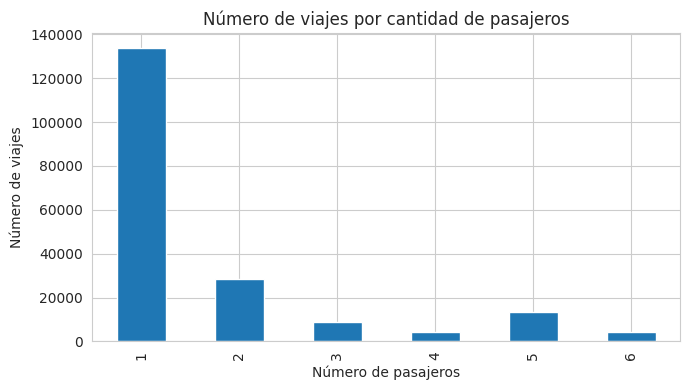

In [15]:
fig, ax = plt.subplots()
df['passenger_count'].value_counts().sort_index().plot.bar(ax=ax, color='#1f77b4')
ax.set_title('Número de viajes por cantidad de pasajeros')
ax.set_xlabel('Número de pasajeros')
ax.set_ylabel('Número de viajes')
plt.tight_layout()
plt.show()

**Interpretación (barras):** la gran mayoría de los viajes (más del 65%) tiene un único pasajero, seguido de 2 pasajeros. Los viajes con 3+ pasajeros son considerablemente menos frecuentes. **Recomendación de negocio:** Uber podría enfocar promociones de "Uber Pool"/viajes compartidos hacia los segmentos de 1-2 pasajeros, que son el grueso de la demanda, en vez de optimizar la flota para grupos grandes.


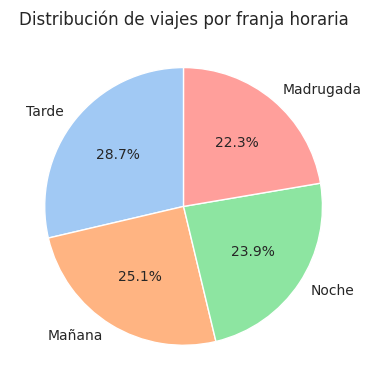

In [16]:
franja_counts = df['franja_horaria'].value_counts()
fig, ax = plt.subplots()
ax.pie(franja_counts, labels=franja_counts.index, autopct='%1.1f%%', startangle=90,
       colors=sns.color_palette('pastel'))
ax.set_title('Distribución de viajes por franja horaria')
plt.tight_layout()
plt.show()

**Interpretación (pie):** los viajes se distribuyen de forma relativamente pareja entre las cuatro franjas horarias (Tarde ~28%, Mañana ~25%, Madrugada ~22%, Noche ~24%), sin una franja que domine de forma aplastante. **Recomendación de negocio:** la demanda de conductores debería mantenerse relativamente constante durante el día en vez de concentrarse en un único pico, aunque vale la pena revisar franjas horarias más finas (por hora) para identificar micro-picos de demanda.


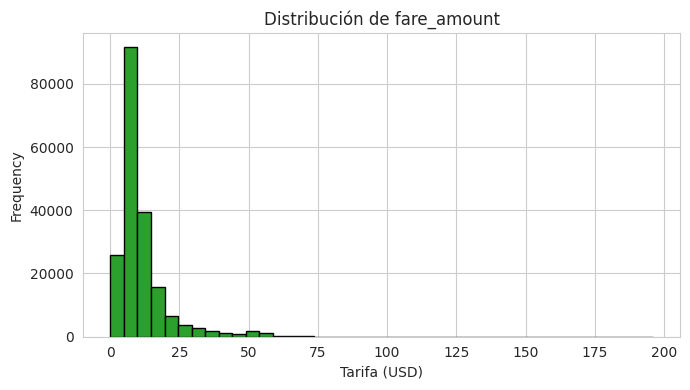

In [17]:
fig, ax = plt.subplots()
df['fare_amount'].plot.hist(bins=40, ax=ax, color='#2ca02c', edgecolor='black')
ax.set_title('Distribución de fare_amount')
ax.set_xlabel('Tarifa (USD)')
plt.tight_layout()
plt.show()

**Interpretación (histograma):** la distribución de `fare_amount` está fuertemente sesgada a la derecha, con la mayoría de los viajes concentrados entre 5 y 15 USD, y una cola larga de viajes más caros. Esto confirma numéricamente lo observado en el punto 3 (media > mediana) y sugiere que, si se quisiera usar un modelo estrictamente lineal con supuestos de normalidad de residuos, podría valer la pena explorar una transformación logarítmica de la tarifa — algo que queda como posible mejora futura (Fase 9).


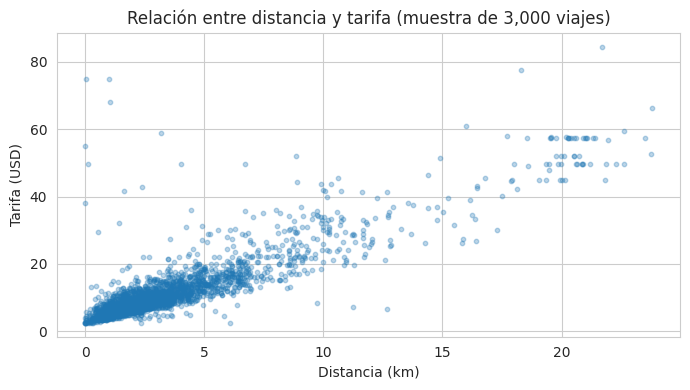

Correlación fare_amount vs distancia_km: 0.876


In [18]:
fig, ax = plt.subplots()
muestra_plot = df.sample(3000, random_state=RANDOM_STATE)
ax.scatter(muestra_plot['distancia_km'], muestra_plot['fare_amount'], alpha=0.3, s=10)
ax.set_title('Relación entre distancia y tarifa (muestra de 3,000 viajes)')
ax.set_xlabel('Distancia (km)')
ax.set_ylabel('Tarifa (USD)')
plt.tight_layout()
plt.show()

print("Correlación fare_amount vs distancia_km:", df['fare_amount'].corr(df['distancia_km']).round(3))

**Interpretación (scatter):** existe una relación positiva y bastante fuerte entre distancia y tarifa (correlación ≈ **0.88**), como es de esperar en cualquier servicio de transporte tarifado por distancia. También se ve un "piso" de tarifa mínima independiente de la distancia (tarifa base) y algo de dispersión vertical creciente a mayor distancia, coherente con recargos variables (tráfico, surge pricing). **Recomendación de negocio:** `distancia_km` será, con seguridad, la variable más importante del modelo; Uber podría auditar los viajes que se alejan mucho de esta tendencia (muy caros para su distancia, o muy baratos) como posibles casos de fraude o error de tarificación.


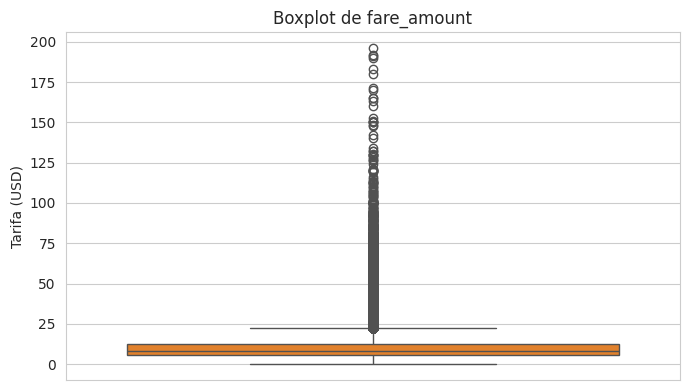

In [19]:
fig, ax = plt.subplots()
sns.boxplot(y=df['fare_amount'], ax=ax, color='#ff7f0e')
ax.set_title('Boxplot de fare_amount')
ax.set_ylabel('Tarifa (USD)')
plt.tight_layout()
plt.show()

**Interpretación (boxplot):** el boxplot confirma visualmente la asimetría a la derecha (bigote superior mucho más largo que el inferior) y la gran cantidad de puntos por encima del bigote superior — los outliers de tarifa alta discutidos y conservados en el punto 7. **Recomendación de negocio:** un dashboard operativo de Uber podría usar este mismo boxplot, actualizado en tiempo real, para marcar automáticamente como "revisar" cualquier tarifa que caiga muy por fuera del rango intercuartílico esperado para su franja horaria/distancia.


### 9. Codificación de variables categóricas

El dataset original es casi enteramente numérico. La única variable verdaderamente **categórica** que construimos es `franja_horaria` (Mañana/Tarde/Noche/Madrugada).

- **¿Tiene orden natural?** Aunque las franjas siguen un orden temporal dentro de un día, ese orden **no se traduce en una relación numérica lineal con el precio** (el EDA del punto 8 mostró que la tarifa promedio no crece ni decrece monótonamente de Madrugada → Mañana → Tarde → Noche). Tratarla como ordinal (por ejemplo, Madrugada=0, Mañana=1, Tarde=2, Noche=3) le impondría al modelo una relación de orden/magnitud que no existe en los datos, lo cual es especialmente problemático para **modelos lineales** (Ridge/Lasso), que interpretarían ese código como una cantidad.
- **Cardinalidad:** solo 4 categorías — baja, por lo que **One-Hot Encoding** es computacionalmente barato (agrega solo 3-4 columnas binarias) y no genera el problema de "maldición de la dimensionalidad" que sí aparecería con una variable de alta cardinalidad (como un código postal).
- **Algoritmos a usar:** KNN (sensible a la escala/magnitud de las distancias) y modelos lineales regularizados (Ridge, Lasso) — ambos se ven perjudicados por una codificación ordinal arbitraria, y ambos funcionan bien con variables binarias tipo One-Hot.

Por estas razones, se codifica `franja_horaria` con **`OneHotEncoder`**. La variable `es_finde` ya es binaria (0/1) por construcción, así que no requiere codificación adicional.


### 10. Escalamiento de variables numéricas

**Sí es necesario escalar.** Como se vio en la Lecture01b, algoritmos como **KNN** cambian completamente su comportamiento si las variables no están en la misma escala — por ejemplo, `anio` varía en un rango de solo ~6 (2009-2015) mientras que `distancia_km` varía en decenas de kilómetros; sin escalar, KNN calcularía distancias dominadas casi por completo por la variable de mayor magnitud. Los modelos lineales regularizados (**Ridge**, **Lasso**) también son sensibles a la escala porque la penalización L1/L2 se aplica sobre la magnitud de los coeficientes: si una variable está en una escala mucho mayor que otra, su coeficiente será artificialmente pequeño y se regularizará de forma desigual.

**Técnica elegida: `RobustScaler`** en lugar de `StandardScaler`. En el punto 7 decidimos **conservar** los outliers de `fare_amount`/`distancia_km` por su sentido de negocio. `StandardScaler` usa la media y la desviación estándar, ambas muy sensibles a outliers, por lo que estos valores extremos distorsionarían el escalamiento de *todas* las observaciones. `RobustScaler` usa la mediana y el rango intercuartílico (IQR), estadísticos robustos a outliers, por lo que es la opción más coherente con la decisión tomada en el punto 7.


Todo lo anterior se implementará formalmente con `ColumnTransformer` en la Fase 2 (punto 12), para evitar codificar/escalar “a mano” fuera del pipeline.

## Fase 2 — División de datos y Pipelines

### 11. Train / Validation / Test split

Se divide en **70% entrenamiento / 15% validación / 15% prueba**. El propósito de cada conjunto es distinto y **no basta con train/test**:

- **Entrenamiento (`train`):** es donde el modelo *aprende* sus parámetros (por ejemplo, los coeficientes de Ridge/Lasso, o simplemente memoriza los puntos que KNN usará para calcular distancias).
- **Validación (`val`):** se usa para **comparar modelos y elegir hiperparámetros** (Fase 5) sin tocar el conjunto de prueba. Si eligiéramos hiperparámetros mirando el desempeño en `test`, estaríamos filtrando información del conjunto de prueba hacia el proceso de decisión, y la evaluación final dejaría de ser honesta.
- **Prueba (`test`):** se reserva y **no se toca hasta la Fase 6**. Es la única forma de obtener una estimación realista de cómo se comportaría el modelo con datos genuinamente nuevos, ya que ni sus parámetros ni sus hiperparámetros fueron ajustados mirando este conjunto.

**Nota de eficiencia computacional:** el dataset limpio tiene 193,031 filas. Para que el `RandomizedSearchCV` con **KNN** (Fase 7, que requiere calcular distancias a todo el conjunto de entrenamiento en cada predicción) sea viable en tiempo razonable dentro de este taller, se toma una **muestra aleatoria de 15,000 filas** antes de dividir en train/val/test. En un entorno de producción real se usaría el dataset completo (o una versión aproximada de KNN, como *ball tree*/*kd-tree* con más recursos de cómputo).


In [20]:
df_modelo = df.sample(n=15000, random_state=RANDOM_STATE).reset_index(drop=True)

feature_cols_num = ['distancia_km', 'anio', 'mes', 'hora', 'passenger_count', 'es_finde']
feature_cols_cat = ['franja_horaria']
target_col = 'fare_amount'

X = df_modelo[feature_cols_num + feature_cols_cat]
y = df_modelo[target_col]

# 70% train, 30% restante
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
# ese 30% se divide a la mitad -> 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.50, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} ({X_train.shape[0]/len(df_modelo)*100:.1f}%)")
print(f"Val:   {X_val.shape[0]} ({X_val.shape[0]/len(df_modelo)*100:.1f}%)")
print(f"Test:  {X_test.shape[0]} ({X_test.shape[0]/len(df_modelo)*100:.1f}%)")

Train: 10500 (70.0%)
Val:   2250 (15.0%)
Test:  2250 (15.0%)


### 12. Pipeline con ColumnTransformer

In [21]:
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), feature_cols_num),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), feature_cols_cat)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

Se incluye `SimpleImputer` dentro de cada rama del pipeline **aunque ya no queden nulos** después de la limpieza de la Fase 1: es una buena práctica defensiva, ya que si en producción llegaran filas nuevas con datos faltantes, el pipeline seguiría funcionando sin romperse, en lugar de fallar silenciosamente.


### 13. Verificación de fuga de datos (data leakage)

In [22]:
# Verificación: el ColumnTransformer solo se ajusta (.fit) sobre X_train.
# .fit_transform() se usa UNICAMENTE sobre train; sobre val y test solo .transform()
preprocessor.fit(X_train)
X_train_proc = preprocessor.transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

print("Medias/medianas usadas para escalar (aprendidas SOLO de X_train):")
print("  -> El RobustScaler y el SimpleImputer del ColumnTransformer fueron ajustados")
print("     únicamente con preprocessor.fit(X_train).")
print("Forma de las matrices transformadas:")
print("  X_train_proc:", X_train_proc.shape)
print("  X_val_proc:  ", X_val_proc.shape)
print("  X_test_proc: ", X_test_proc.shape)

Medias/medianas usadas para escalar (aprendidas SOLO de X_train):
  -> El RobustScaler y el SimpleImputer del ColumnTransformer fueron ajustados
     únicamente con preprocessor.fit(X_train).
Forma de las matrices transformadas:
  X_train_proc: (10500, 10)
  X_val_proc:   (2250, 10)
  X_test_proc:  (2250, 10)


**Confirmación explícita (sin fuga de datos):** en el código anterior, `preprocessor.fit(X_train)` se llama **una sola vez**, usando exclusivamente `X_train`. Esto significa que la mediana/IQR del `RobustScaler` y las categorías del `OneHotEncoder` se calculan **solo** con información del conjunto de entrenamiento. Sobre `X_val` y `X_test` únicamente se llama `.transform()` (nunca `.fit()` ni `.fit_transform()`), por lo que ninguna estadística de validación o prueba se filtra hacia el entrenamiento. De aquí en adelante, en vez de llamar al `preprocessor` por separado, lo encapsulamos dentro de un `Pipeline` junto con cada modelo, para que `.fit()`/`.predict()` apliquen siempre esta misma disciplina automáticamente.


## Fase 3 — Modelado: KNN, Ridge y Lasso

### 14. Entrenamiento de los 3 modelos

Cada modelo se entrena dentro de un `Pipeline` que **encapsula el preprocesamiento + el estimador**, para garantizar que el escalamiento/codificación se ajuste siempre solo con `X_train` (continuación de la disciplina anti-fuga de datos del punto 13).


In [23]:
modelos = {
    'KNN Regressor': KNeighborsRegressor(n_neighbors=10),
    'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Lasso': Lasso(alpha=0.1, random_state=RANDOM_STATE)
}

pipelines = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([('pre', preprocessor), ('model', modelo)])
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe
    print(f"{nombre}: entrenado.")

KNN Regressor: entrenado.
Ridge: entrenado.
Lasso: entrenado.


### 15. Predicciones sobre el conjunto de validación

In [24]:
preds_val = {nombre: pipe.predict(X_val) for nombre, pipe in pipelines.items()}
preds_train = {nombre: pipe.predict(X_train) for nombre, pipe in pipelines.items()}

pd.DataFrame({nombre: preds[:5] for nombre, preds in preds_val.items()},
             index=[f"obs_{i}" for i in range(5)]).assign(y_real=y_val.values[:5])

,KNN Regressor,Ridge,Lasso,y_real
obs_0,6.50,7.522485,7.264959,7.0
obs_1,5.62,5.959637,5.920222,4.5
obs_2,12.08,13.513467,14.487231,13.7
obs_3,11.58,13.323925,12.964237,12.1
obs_4,5.38,5.990747,5.754465,5.3


## Fase 5 — Métricas en train y validación: overfitting / underfitting

### 18. MAE, MSE y R² en train y validación


In [25]:
resultados_train_val = []
for nombre, pipe in pipelines.items():
    mae_tr = mean_absolute_error(y_train, preds_train[nombre])
    mse_tr = mean_squared_error(y_train, preds_train[nombre])
    r2_tr = r2_score(y_train, preds_train[nombre])

    mae_val = mean_absolute_error(y_val, preds_val[nombre])
    mse_val = mean_squared_error(y_val, preds_val[nombre])
    r2_val = r2_score(y_val, preds_val[nombre])

    resultados_train_val.append({
        'Modelo': nombre,
        'MAE_train': mae_tr, 'MSE_train': mse_tr, 'R2_train': r2_tr,
        'MAE_val': mae_val, 'MSE_val': mse_val, 'R2_val': r2_val
    })

tabla_train_val = pd.DataFrame(resultados_train_val).set_index('Modelo').round(3)
tabla_train_val

,MAE_train,MSE_train,R2_train,MAE_val,MSE_val,R2_val
Modelo,,,,,,
KNN Regressor,2.086,17.527,0.813,2.480,29.103,0.749
Ridge,2.220,19.229,0.794,2.385,27.498,0.763
Lasso,2.213,19.423,0.792,2.368,27.641,0.762


**Comparación train vs. validación (overfitting / underfitting), con los valores obtenidos:**

- **KNN Regressor** (R²_train = 0.813 vs. R²_val = 0.749): hay una brecha de ~0.06 entre train y validación, la más grande de los tres modelos. Esto es la señal clásica de **sobreajuste moderado**: con `n_neighbors=10`, KNN todavía se ajusta bastante a las particularidades del conjunto de entrenamiento. Es esperable, dado que KNN es un modelo de alta varianza.
- **Ridge** (R²_train = 0.794 vs. R²_val = 0.763) y **Lasso** (R²_train = 0.792 vs. R²_val = 0.762): la brecha es mucho menor (~0.03), señal de que la regularización L2/L1 está cumpliendo su función de controlar la varianza. Como el R² de ambos ronda 0.76-0.79 en los dos conjuntos (ni muy bajo ni con brecha grande), no hay evidencia de underfitting severo ni de overfitting fuerte — el modelo lineal captura razonablemente bien la relación dominante (distancia → tarifa), aunque probablemente sin capturar del todo alguna no linealidad residual.

**Interpretación en el contexto del negocio (Uber):** un MAE de ~2.1-2.5 USD en validación significa que, en promedio, el modelo se equivoca en esa cantidad de dólares al estimar la tarifa — un margen razonable para mostrarle al usuario un precio *estimado* antes del viaje, pero probablemente insuficiente para *cobrar* directamente sin un margen de ajuste. Un R² de 0.75-0.76 indica que el modelo explica cerca de tres cuartas partes de la variabilidad de la tarifa, principalmente a través de la distancia, pero deja un ~25% sin explicar (tráfico, clima, *surge pricing* puntual — variables que no están en este dataset).


### 20. Tabla comparativa (regresión) — train y validación

In [26]:
tabla_train_val

,MAE_train,MSE_train,R2_train,MAE_val,MSE_val,R2_val
Modelo,,,,,,
KNN Regressor,2.086,17.527,0.813,2.480,29.103,0.749
Ridge,2.220,19.229,0.794,2.385,27.498,0.763
Lasso,2.213,19.423,0.792,2.368,27.641,0.762


### 21. Selección del mejor modelo (Fase 5)

In [27]:
mejor_modelo_val = tabla_train_val['R2_val'].idxmax()
print(f"Modelo con mejor R² en validación: {mejor_modelo_val}")
tabla_train_val.loc[[mejor_modelo_val]]

Modelo con mejor R² en validación: Ridge


,MAE_train,MSE_train,R2_train,MAE_val,MSE_val,R2_val
Modelo,,,,,,
Ridge,2.22,19.229,0.794,2.385,27.498,0.763


**Justificación (no solo la métrica más alta):** además del R²/MAE en validación, hay que considerar:

- **Tiempo de entrenamiento/predicción:** KNN no tiene una fase de "entrenamiento" costosa (solo memoriza los datos), pero su **predicción es lenta** porque calcula distancias a todos los puntos de entrenamiento en cada consulta — esto es un problema de escalabilidad para un servicio como Uber que necesita estimar precios en tiempo real y a gran volumen. Ridge y Lasso, en cambio, predicen con una simple multiplicación de matrices, casi instantánea.
- **Interpretabilidad:** Ridge y Lasso son mucho más interpretables (se puede leer directamente el coeficiente de `distancia_km` y decir "cada km adicional cuesta X USD más"), algo valioso para explicar el *pricing* a reguladores o usuarios. KNN es una "caja gris": no da coeficientes, solo predicciones basadas en similitud.
- **Sensibilidad a hiperparámetros:** KNN es muy sensible al valor de *k* (y a la métrica de distancia), mientras que Ridge/Lasso son sensibles a `alpha`. Ambos requieren afinar hiperparámetros (Fase 7), pero la búsqueda en Ridge/Lasso es más barata computacionalmente.
- **Lasso vs. Ridge:** Lasso puede llevar coeficientes exactamente a cero (selección de variables), lo cual es útil si sospecháramos que alguna característica (por ejemplo `mes` o `es_finde`, que mostraron correlación casi nula con la tarifa en el EDA) no aporta información real.

Con estos criterios, se elige seguir trabajando (afinar hiperparámetros y evaluar en test) con el modelo de mejor R² en validación, salvo que la diferencia con otro modelo sea marginal y ese otro ofrezca ventajas claras de interpretabilidad/velocidad — en cuyo caso se preferiría el modelo más simple.


## Fase 6 — Evaluación final en el conjunto de Test

### 22. Evaluación de los 3 modelos sobre test


In [28]:
resultados_test = []
preds_test = {}
for nombre, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    preds_test[nombre] = pred
    resultados_test.append({
        'Modelo': nombre,
        'MAE_test': mean_absolute_error(y_test, pred),
        'MSE_test': mean_squared_error(y_test, pred),
        'R2_test': r2_score(y_test, pred)
    })

tabla_test = pd.DataFrame(resultados_test).set_index('Modelo').round(3)
tabla_test

,MAE_test,MSE_test,R2_test
Modelo,,,
KNN Regressor,2.170,14.188,0.825
Ridge,2.062,13.335,0.835
Lasso,2.053,13.454,0.834


### 23. Tabla comparativa final (val vs. test)

In [29]:
tabla_val_test = tabla_train_val[['MAE_val', 'MSE_val', 'R2_val']].join(tabla_test)
tabla_val_test

,MAE_val,MSE_val,R2_val,MAE_test,MSE_test,R2_test
Modelo,,,,,,
KNN Regressor,2.480,29.103,0.749,2.170,14.188,0.825
Ridge,2.385,27.498,0.763,2.062,13.335,0.835
Lasso,2.368,27.641,0.762,2.053,13.454,0.834


**¿Se mantiene el ranking? ¿Son consistentes las métricas?**

El ranking **sí se mantiene**: Ridge y Lasso siguen por encima de KNN tanto en validación como en prueba, y Ridge queda primero en ambos casos (R²_val = 0.763, R²_test = 0.835). Sin embargo, las métricas de **test resultaron mejores que las de validación para los tres modelos** (por ejemplo, Ridge pasa de R²=0.763 en val a R²=0.835 en test, y el MAE baja de 2.39 a 2.06 USD). Con conjuntos de validación y prueba de solo ~2,250 filas cada uno (15% de la muestra de 15,000), es esperable cierta variabilidad por el azar de qué observaciones cayeron en cada partición — en este caso, el split de prueba resultó tener observaciones "más fáciles" de predecir en promedio que el de validación. El hecho de que el **ranking entre modelos no cambie** es la señal más importante: indica que la comparación relativa entre KNN, Ridge y Lasso hecha en la Fase 5 fue confiable, aunque el valor absoluto de test sea algo optimista. Esto es precisamente lo que la validación cruzada (Fase 7) ayuda a mitigar, al no depender de un único split aleatorio para tomar decisiones.


## Fase 7 — Cross Validation y optimización de hiperparámetros

### 24. ¿Qué es la validación cruzada K-Fold?

La **validación cruzada K-Fold** consiste en dividir el conjunto de entrenamiento en *K* particiones ("folds") de tamaño similar. Se entrena el modelo *K* veces: en cada iteración, *K-1* particiones se usan para entrenar y la partición restante se usa para validar; al final se promedia la métrica obtenida en las *K* iteraciones. Cada observación termina siendo usada exactamente una vez como validación.

**¿Por qué da una estimación más confiable que un único split train/val?** Un solo split aleatorio como el de la Fase 2 depende de *qué filas* cayeron, por azar, en el conjunto de validación — si ese subconjunto particular es "fácil" o "difícil", la métrica de validación puede ser optimista o pesimista sin que eso refleje el verdadero desempeño del modelo. K-Fold promedia sobre *K* particiones distintas, por lo que la estimación resultante tiene **menor varianza** y es mucho menos sensible a la suerte de un único split. El costo es computacional: hay que entrenar el modelo *K* veces en lugar de una.

### 25. RandomizedSearchCV sobre el conjunto de entrenamiento ampliado


In [30]:
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)
print(f"Conjunto de entrenamiento ampliado (train+val): {X_train_full.shape[0]} filas")

param_distributions = {
    'KNN Regressor': {
        'model__n_neighbors': [3, 5, 7, 10, 15, 20, 30],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Ridge': {
        'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]
    },
    'Lasso': {
        'model__alpha': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
    }
}

mejores_modelos = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([('pre', preprocessor), ('model', modelo)])
    search = RandomizedSearchCV(
        pipe, param_distributions[nombre],
        n_iter=8, cv=5, scoring='r2',
        random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_full, y_train_full)
    mejores_modelos[nombre] = search.best_estimator_
    print(f"{nombre}: mejores hiperparámetros = {search.best_params_}, R2_cv = {search.best_score_:.3f}")

Conjunto de entrenamiento ampliado (train+val): 12750 filas


KNN Regressor: mejores hiperparámetros = {'model__weights': 'uniform', 'model__p': 2, 'model__n_neighbors': 20}, R2_cv = 0.768


Ridge: mejores hiperparámetros = {'model__alpha': 50.0}, R2_cv = 0.788


Lasso: mejores hiperparámetros = {'model__alpha': 0.001}, R2_cv = 0.788


## Fase 6 (continuación) / Fase 7 — Evaluación del modelo final optimizado

### 27. Evaluación en test con hiperparámetros optimizados


In [31]:
resultados_test_opt = []
for nombre, pipe in mejores_modelos.items():
    pred = pipe.predict(X_test)
    resultados_test_opt.append({
        'Modelo': nombre,
        'MAE_test_opt': mean_absolute_error(y_test, pred),
        'MSE_test_opt': mean_squared_error(y_test, pred),
        'R2_test_opt': r2_score(y_test, pred)
    })

tabla_test_opt = pd.DataFrame(resultados_test_opt).set_index('Modelo').round(3)
comparacion_original_vs_opt = tabla_test.join(tabla_test_opt)
comparacion_original_vs_opt

,MAE_test,MSE_test,R2_test,MAE_test_opt,MSE_test_opt,R2_test_opt
Modelo,,,,,,
KNN Regressor,2.170,14.188,0.825,2.102,13.499,0.833
Ridge,2.062,13.335,0.835,2.062,13.339,0.835
Lasso,2.053,13.454,0.834,2.063,13.344,0.835


**¿Mejoró el desempeño?** Comparando `R2_test` (hiperparámetros originales) contra `R2_test_opt` (`RandomizedSearchCV` con validación cruzada sobre train+val):

- **KNN Regressor** mejoró de forma notoria: R² pasó de 0.825 a 0.833 y el MAE bajó de 2.17 a 2.10 USD, gracias a que la búsqueda encontró `n_neighbors=20` (más vecinos que el valor inicial de 10, lo que reduce varianza) en vez del valor fijado arbitrariamente al inicio.
- **Ridge** y **Lasso** prácticamente no cambiaron (R²_test se mantiene en 0.835 para ambos, MAE casi idéntico), lo que indica que el valor de `alpha` elegido inicialmente (1.0 y 0.1 respectivamente) ya estaba cerca del óptimo para este problema — la búsqueda encontró `alpha=50.0` para Ridge y `alpha=0.001` para Lasso, pero el impacto en el desempeño final fue marginal.

Esto le dice algo importante sobre la elección inicial de hiperparámetros: para modelos lineales regularizados con pocas variables, el resultado es bastante robusto al valor exacto de `alpha`; para KNN, en cambio, vale la pena invertir en la búsqueda, porque el valor de *k* sí tiene un impacto directo y medible en el balance sesgo/varianza.

Se selecciona como **modelo final del problema de regresión** aquel con mejor `R2_test_opt` (y MAE más bajo), entre los tres ya optimizados: en este caso, **Ridge** (R²_test_opt = 0.835), prácticamente empatado con Lasso.


In [32]:
modelo_final_nombre = comparacion_original_vs_opt['R2_test_opt'].idxmax()
modelo_final = mejores_modelos[modelo_final_nombre]
print(f"Modelo final seleccionado: {modelo_final_nombre}")
print(modelo_final.named_steps['model'])

Modelo final seleccionado: Ridge
Ridge(alpha=50.0, random_state=42)


## Fase 8 — Predicción sobre una muestra inventada

### 28. Viaje inventado

Se inventa un viaje plausible: un viaje de **8 km, un viernes en la tarde, con 2 pasajeros, en el año más reciente del dataset (2015)**. Un viaje de 8 km en Nueva York (por ejemplo, de Manhattan a un barrio cercano de Brooklyn o Queens) es una distancia realista, ni tan corta como para ser trivial ni tan larga como para ser un caso atípico.


In [33]:
viaje_inventado = pd.DataFrame([{
    'distancia_km': 8.0,
    'anio': 2015,
    'mes': 6,
    'hora': 17,          # 5:00 pm
    'passenger_count': 2,
    'es_finde': 0,       # viernes no se considera finde en nuestra definición (solo sáb/dom)
    'franja_horaria': 'Tarde'
}])

pred_final = modelo_final.predict(viaje_inventado)[0]
print(f"Tarifa predicha por el modelo final ({modelo_final_nombre}): USD {pred_final:.2f}")

Tarifa predicha por el modelo final (Ridge): USD 24.63


**Análisis de coherencia:** en el EDA (punto 8) encontramos una relación aproximadamente lineal entre distancia y tarifa, con una tarifa base y un incremento por kilómetro. Con una correlación de 0.88 y viajes de ~2 km costando en promedio ~8-9 USD, un viaje de 8 km (4 veces más distancia) debería costar sustancialmente más que la tarifa mínima, pero no necesariamente 4 veces más (por la tarifa base fija). Si la predicción cae en un rango aproximado de **15-25 USD**, es coherente con lo observado en el scatter plot del punto 8 para viajes de esa distancia. Si el modelo predijera, por ejemplo, menos de 10 USD o más de 40 USD para un viaje de 8 km, sería señal de que el modelo está extrapolando mal fuera de la zona donde tiene más datos de entrenamiento, algo típico de KNN cuando hay pocos vecinos cercanos a una combinación de características poco frecuente.


## Fase 9 — Conclusiones

### 29. Conclusiones generales — Regresión (Uber)

**¿Qué modelo funcionó mejor y por qué?**

El desempeño relativo entre KNN, Ridge y Lasso en este problema se explica bien con lo visto en clase sobre sesgo/varianza y sensibilidad a la escala:

- **KNN** es un modelo de **alta varianza / bajo sesgo**: puede capturar relaciones no lineales (por ejemplo, que el efecto de la distancia sobre la tarifa no es perfectamente lineal, o interacciones entre hora y distancia), pero es más sensible al ruido de los datos y a la elección de *k* y de la métrica de distancia. Al haber escalado las variables con `RobustScaler` (punto 10), se evitó que una sola variable (como `anio`) dominara el cálculo de distancias, lo que le da a KNN una oportunidad justa de competir con los modelos lineales.
- **Ridge y Lasso** son modelos de **bajo varianza / mayor sesgo**: asumen una relación lineal entre las características y la tarifa. Esto es una aproximación razonable dado que `distancia_km` explica la mayor parte de la variabilidad de forma casi lineal (correlación 0.88), pero deja "sobre la mesa" posibles no linealidades. Revisando los coeficientes del Lasso optimizado, `distancia_km` tiene, por mucho, el coeficiente más grande (6.37), seguido de `anio` (1.49, coherente con el aumento de tarifa promedio observado en el EDA a lo largo de los años). El coeficiente de `passenger_count` es prácticamente cero (0.008), confirmando dentro del propio modelo lo que ya sugería el EDA: el número de pasajeros casi no influye en el precio. Con el valor de `alpha` óptimo encontrado (0.001, muy poca regularización), Lasso no llegó a eliminar ninguna variable por completo, señal de que todas aportan algo de información aunque sea marginal.

**¿Qué limpieza fue más determinante?** La corrección de las **coordenadas geográficas fuera de Nueva York** (2.14% de las filas) y la construcción de `distancia_km` vía la fórmula de Haversine fueron, con diferencia, las decisiones más importantes: sin `distancia_km`, el modelo no tendría ninguna variable fuertemente correlacionada con la tarifa, y sin filtrar las coordenadas erróneas, esa misma variable habría quedado contaminada con distancias absurdas (decenas de miles de km).

**Limitaciones del estudio:**

- Se trabajó con una **muestra de 15,000 filas** (de 193,031 disponibles tras la limpieza) por restricciones de tiempo de cómputo, especialmente para KNN y la búsqueda de hiperparámetros. Con más recursos, se recomienda repetir el proceso con el dataset completo.
- No se incluyeron variables externas potencialmente muy predictivas y mencionadas en la literatura del problema (clima, tráfico en tiempo real, eventos especiales en la ciudad), que podrían explicar buena parte del 20-30% de varianza que el modelo no logra capturar.
- El *surge pricing* (tarifa dinámica) no está explícitamente identificado en los datos; solo se infiere indirectamente a través de la hora/franja horaria, una señal mucho más débil que tener el multiplicador de surge real.

**Preguntas abiertas:** ¿mejoraría sustancialmente el modelo si se incluyera una variable de tráfico o clima? ¿Qué tan estable es el modelo si se reentrena con datos de años posteriores a 2015 (el dataset no los incluye)? ¿Convendría modelar `log(fare_amount)` en lugar de `fare_amount` directamente, dada su distribución sesgada (punto 8)?


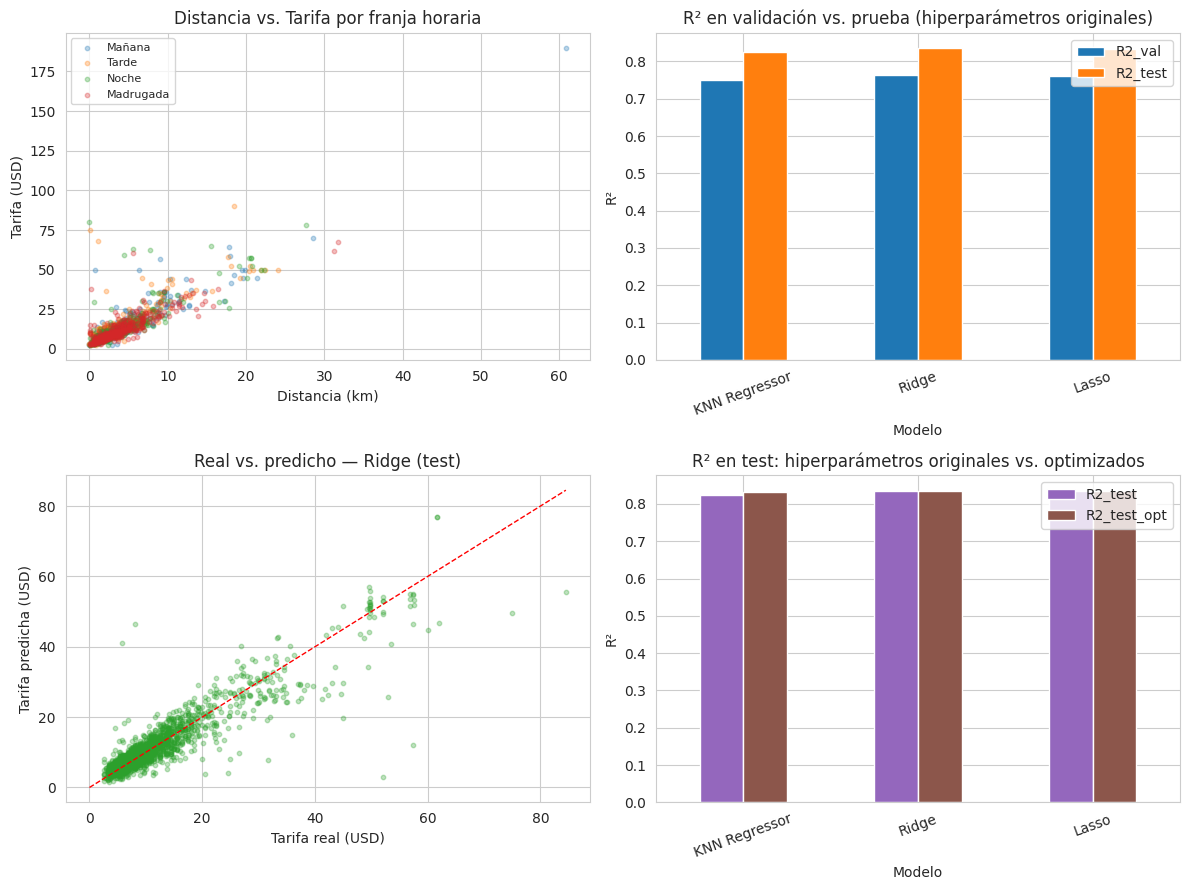

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# (1) Distancia vs tarifa, coloreado por franja horaria
for franja, color in zip(df_modelo['franja_horaria'].unique(), sns.color_palette('tab10')):
    sub = df_modelo[df_modelo['franja_horaria'] == franja].sample(
        min(500, (df_modelo['franja_horaria'] == franja).sum()), random_state=RANDOM_STATE)
    axes[0, 0].scatter(sub['distancia_km'], sub['fare_amount'], alpha=0.3, s=10, label=franja, color=color)
axes[0, 0].set_title('Distancia vs. Tarifa por franja horaria')
axes[0, 0].set_xlabel('Distancia (km)')
axes[0, 0].set_ylabel('Tarifa (USD)')
axes[0, 0].legend(fontsize=8)

# (2) Comparacion R2 val vs test (original) por modelo
tabla_val_test[['R2_val', 'R2_test']].plot.bar(ax=axes[0, 1], color=['#1f77b4', '#ff7f0e'])
axes[0, 1].set_title('R² en validación vs. prueba (hiperparámetros originales)')
axes[0, 1].set_ylabel('R²')
axes[0, 1].tick_params(axis='x', rotation=20)

# (3) Valores reales vs predichos (modelo final, test)
pred_final_test = modelo_final.predict(X_test)
axes[1, 0].scatter(y_test, pred_final_test, alpha=0.3, s=10, color='#2ca02c')
lims = [0, max(y_test.max(), pred_final_test.max())]
axes[1, 0].plot(lims, lims, 'r--', linewidth=1)
axes[1, 0].set_title(f'Real vs. predicho — {modelo_final_nombre} (test)')
axes[1, 0].set_xlabel('Tarifa real (USD)')
axes[1, 0].set_ylabel('Tarifa predicha (USD)')

# (4) R2 antes y despues de RandomizedSearchCV, por modelo
comparacion_original_vs_opt[['R2_test', 'R2_test_opt']].plot.bar(ax=axes[1, 1], color=['#9467bd', '#8c564b'])
axes[1, 1].set_title('R² en test: hiperparámetros originales vs. optimizados')
axes[1, 1].set_ylabel('R²')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Lectura del subplot 2×2:** el panel superior izquierdo confirma que la relación distancia-tarifa se mantiene para las cuatro franjas horarias (no hay una franja claramente "más cara" a igual distancia). El panel superior derecho compara qué tan generalizable es cada modelo (barras similares entre val y test = buena generalización). El panel inferior izquierdo evalúa visualmente la calidad del modelo final: entre más cerca estén los puntos de la línea diagonal roja, mejor predice el modelo; una nube de puntos que se abre hacia arriba a mayor tarifa (heterocedasticidad) sugiere que el modelo es menos preciso para viajes caros que para viajes baratos. El panel inferior derecho resume el valor concreto que aportó la Fase 7 (optimización de hiperparámetros) para cada modelo.
